In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
#from sklearn.preprocessing import StandardScaler 

In [33]:
df = pd.read_csv('qc_batch_data.csv')
df.head(5)

,Batch_ID,Moisture_Pct,pH,Oven_Temp_C,Mixing_Time_min,Gluten_Trace_ppm,QC_Pass
0,B001,12.07,6.65,195.5,16.9,2.88,1
1,B002,11.21,7.03,191.9,13.6,0.38,0
2,B003,12.27,5.77,185.4,13.0,2.36,1
3,B004,13.46,6.51,180.1,15.0,0.65,1
4,B005,11.08,6.05,190.2,14.6,9.08,1


### 1. Exploratory Data Analysis (EDA)

Before training the machine learning model, we inspect the behavior of the simulated dataset (500 production batches) through three charts to gain a clearer view of the quality control (QC) status:

1. **Pass vs. Fail Batch Distribution:** Checks class balance and the overall ratio of passed batches (1) to failed batches (0).
2. **Moisture % vs. Oven Temp (°C):** Visualizes the acceptable process window (gray dashed lines); batches falling outside this window generally fail quality control.
3. **Gluten Trace Distribution:** Examines the spread of gluten trace levels across batches relative to the international gluten-free standard limit (below 20 ppm).

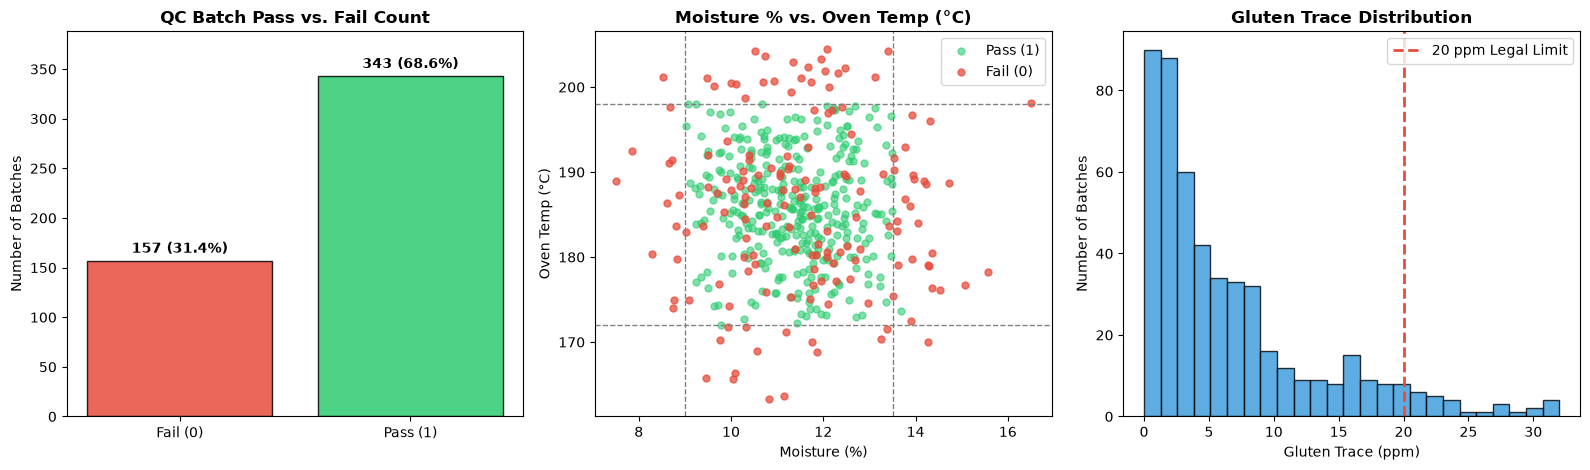

In [60]:
# Create a 1x3 layout for exploratory plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Pass vs. Fail Count
counts = df["QC_Pass"].value_counts().sort_index()
axes[0].bar(["Fail (0)", "Pass (1)"], counts.values, color=["#e74c3c", "#2ecc71"], edgecolor="black", alpha=0.85)
axes[0].set_title("QC Batch Pass vs. Fail Count", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Number of Batches")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 8, f"{v} ({v/len(df)*100:.1f}%)", ha="center", fontweight="bold")
axes[0].set_ylim(0, max(counts.values) + 45)

# 2. Moisture % vs. Oven Temp (°C) with Safe Window
passed = df[df["QC_Pass"] == 1]
failed = df[df["QC_Pass"] == 0]

axes[1].scatter(passed["Moisture_Pct"], passed["Oven_Temp_C"], color="#2ecc71", alpha=0.6, label="Pass (1)", s=25)
axes[1].scatter(failed["Moisture_Pct"], failed["Oven_Temp_C"], color="#e74c3c", alpha=0.75, label="Fail (0)", s=25)
axes[1].axvline(9.0, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(13.5, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(172.0, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(198.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Moisture % vs. Oven Temp (°C)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Moisture (%)")
axes[1].set_ylabel("Oven Temp (°C)")
axes[1].legend()

# 3. Gluten Trace Distribution with 20 ppm Legal Limit
axes[2].hist(df["Gluten_Trace_ppm"], bins=25, color="#3498db", edgecolor="black", alpha=0.8)
axes[2].axvline(20.0, color="#e74c3c", linestyle="--", linewidth=2, label="20 ppm Legal Limit")
axes[2].set_title("Gluten Trace Distribution", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Gluten Trace (ppm)")
axes[2].set_ylabel("Number of Batches")
axes[2].legend()

plt.tight_layout()
plt.show()

### 2. Data Preparation & Model Training
In this step, we define the five key quality control parameters (Moisture, pH, Oven Temperature, Mixing Time, and Gluten Trace) as input features and the final QC outcome as the target variable. We then split the dataset into **80% Training** and **20% Testing** sets for later evaluation, and train a Decision Tree classifier to learn the patterns and acceptable pass limits for each batch.

In [61]:
X = df[['Moisture_Pct','pH','Oven_Temp_C','Mixing_Time_min','Gluten_Trace_ppm']].values
Y = df['QC_Pass']
train_x, test_x, train_y, test_y = train_test_split(X, Y, test_size=0.2, random_state=4)
QCTree = DecisionTreeClassifier(criterion="entropy", max_depth = 9, random_state=4)
QCTree.fit(train_x,train_y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",4
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

### 3. Model Evaluation & Feature Importance
Here we evaluate the trained model on the unseen test set (100 batches):

1. **Accuracy:** The model predicts batch pass/fail status with **95%** accuracy.
2. **Confusion Matrix:** Displays the breakdown of correct and incorrect predictions, particularly tracking False Positives—which are critical in food quality control (only 2 missed failed batches).
3. **Feature Importance:** Highlights which process and laboratory parameters contribute most to the model's decisions and QC failures.


In [57]:
predTree = QCTree.predict(test_x)
print("DecisionTrees's Accuracy: ", metrics.accuracy_score(test_y, predTree))

DecisionTrees's Accuracy:  0.95


              precision    recall  f1-score   support

    Fail (0)       0.89      0.93      0.91        27
    Pass (1)       0.97      0.96      0.97        73

    accuracy                           0.95       100
   macro avg       0.93      0.94      0.94       100
weighted avg       0.95      0.95      0.95       100



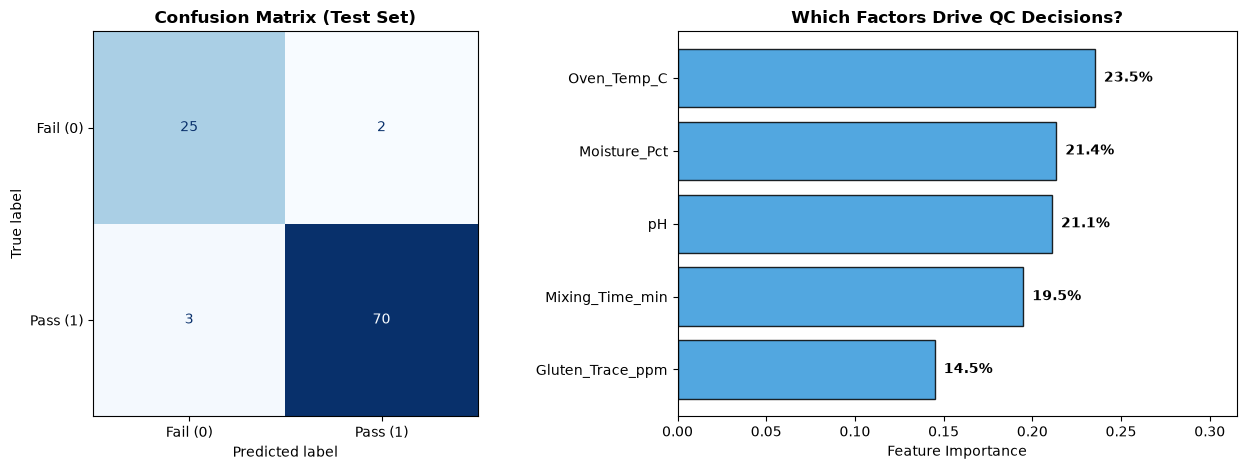

In [58]:
feature_names = ['Moisture_Pct', 'pH', 'Oven_Temp_C', 'Mixing_Time_min', 'Gluten_Trace_ppm']

# Print precision, recall, and F1-score
print(metrics.classification_report(test_y, predTree, target_names=["Fail (0)", "Pass (1)"]))

# Plot Confusion Matrix & Feature Importance side-by-side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Confusion Matrix
cm = metrics.confusion_matrix(test_y, predTree)
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail (0)", "Pass (1)"])
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (Test Set)", fontsize=12, fontweight="bold")

# 2. Feature Importance
importances = QCTree.feature_importances_
sorted_idx = importances.argsort()
axes[1].barh([feature_names[i] for i in sorted_idx], importances[sorted_idx], color="#3498db", edgecolor="black", alpha=0.85)
axes[1].set_title("Which Factors Drive QC Decisions?", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Feature Importance")
for i, v in enumerate(importances[sorted_idx]):
    axes[1].text(v + 0.005, i, f"{v*100:.1f}%", va="center", fontweight="bold")
axes[1].set_xlim(0, max(importances) + 0.08)

plt.tight_layout()
plt.show()